In [35]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import linear_model

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score, root_mean_squared_error, mean_squared_error
from sklearn.pipeline import Pipeline

# Polynomial Regression
#### Nümunə
$$
y = 0.5x^3 - 3x^2 + 2x + noise
$$

In [36]:
n = 120
X = np.linspace(-4, 6, n).reshape(-1, 1)
noise = np.random.normal(0, 6, n)

In [37]:
y = 0.5 * X.flatten()**3 - 3*X.flatten()**2 + 2*X.flatten() + noise

In [38]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
len(X_train), len(X_test)

(90, 30)

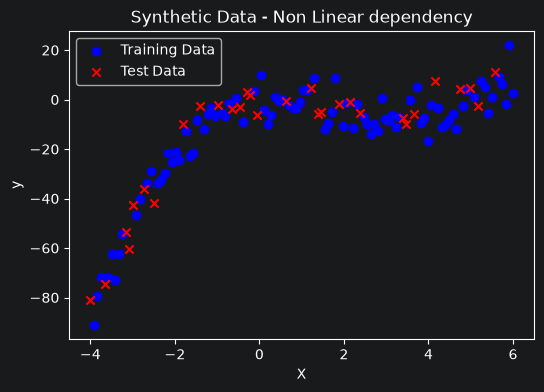

In [39]:
plt.figure(figsize=(6, 4))
plt.scatter(X_train, y_train, color='blue', label='Training Data')
plt.scatter(X_test, y_test, color='red', label='Test Data', marker='x')
plt.title('Synthetic Data - Non Linear dependency')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.show()

In [40]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred_train_lin = linear_model.predict(X_train)
y_pred_test_lin = linear_model.predict(X_test)

r2_train_lin = r2_score(y_train, y_pred_train_lin)
r2_test_lin = r2_score(y_test, y_pred_test_lin)

rmse_train_lin = np.sqrt(mean_squared_error(y_train, y_pred_train_lin))
rmse_test_lin = mean_squared_error(y_test, y_pred_test_lin) ** 0.5

print(f"""
Linear Regression:
    Train RMSE: {rmse_train_lin:.3f}, Test RMSE: {rmse_test_lin:.3f}
    Train R2: {r2_train_lin:.3f}, Test R2: {r2_test_lin:.3f}
""")


Linear Regression:
    Train RMSE: 15.307, Test RMSE: 16.844
    Train R2: 0.492, Test R2: 0.532



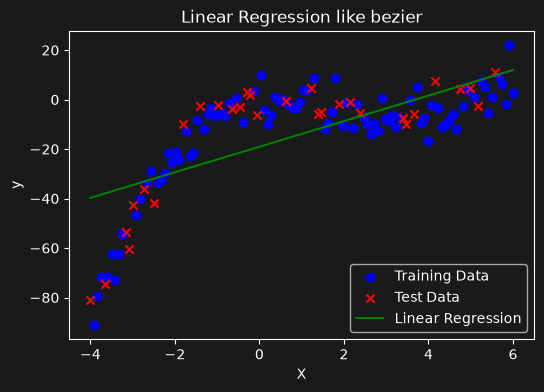

In [41]:
X_grid = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
y_grid_lin = linear_model.predict(X_grid)

plt.figure(figsize=(6, 4))
plt.scatter(X_train, y_train, color='blue', label='Training Data')
plt.scatter(X_test, y_test, color='red', label='Test Data', marker='x')
plt.plot(X_grid, y_grid_lin, color='green', label='Linear Regression')
plt.title('Linear Regression like bezier')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.show()

In [42]:
poly_pipe = Pipeline([
    ('poly', PolynomialFeatures(include_bias=False)),
    ('lin', LinearRegression())
])


param_grid = {
    'poly__degree': list(range(1, 11)),
}

cv  = KFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(
    estimator=poly_pipe,
    param_grid=param_grid,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

grid.fit(X_train, y_train)
best_degree = grid.best_params_['poly__degree']
best_cv_rmse = -grid.best_score_

print(f"""
Polynomial best degree is: {best_degree}
Best CV RMSE: {best_cv_rmse:.3f}
""")


Polynomial best degree is: 3
Best CV RMSE: 5.468



In [43]:
rows = []
for d in range(1, 11):
    pipe = Pipeline([
    ('poly', PolynomialFeatures(include_bias=False, degree=d)),
    ('lin', LinearRegression())
])
    pipe.fit(X_train, y_train)
    y_tr = pipe.predict(X_train)
    y_te = pipe.predict(X_test)

    rows.append(
        {
            'degree': d,
            'train_rmse': root_mean_squared_error(y_train, y_tr),
            'test_rmse': root_mean_squared_error(y_test, y_te),
            'train_r2': r2_score(y_train, y_train),
            'test_r2': r2_score(y_test, y_te),
        }
    )

metrics_df = pd.DataFrame(rows).set_index("degree")
metrics_df

,train_rmse,test_rmse,train_r2,test_r2
degree,,,,
1,15.306701,16.844079,1.0,0.532213
2,10.926437,10.650113,1.0,0.812991
3,5.373235,5.844456,1.0,0.943683
4,5.366953,5.832493,1.0,0.943913
5,5.351169,5.659752,1.0,0.947186
6,5.345327,5.734709,1.0,0.945778
7,5.343186,5.782821,1.0,0.944864
8,5.348578,5.894853,1.0,0.942707
9,5.549161,5.932617,1.0,0.941971


In [47]:
best_model = Pipeline([
    ('poly', PolynomialFeatures(include_bias=False, degree=best_degree)),
    ('lin', LinearRegression())
])
best_model.fit(X_train, y_train)
y_best_tr = best_model.predict(X_train)
y_best_ts = best_model.predict(X_test)


print(f"""
Best model:
    Best model degree is: {best_degree}
    Best Train RMSE: {root_mean_squared_error(y_train, y_best_tr):.3f}
    Best Test RMSE: {root_mean_squared_error(y_test, y_best_ts):.3f}
    Best Train R2: {r2_score(y_train, y_best_tr):.3f}
    Best Test R2: {r2_score(y_test, y_best_ts):.3f}
""")


Best model:
    Best model degree is: 3
    Best Train RMSE: 5.373
    Best Test RMSE: 5.844
    Best Train R2: 0.937
    Best Test R2: 0.944



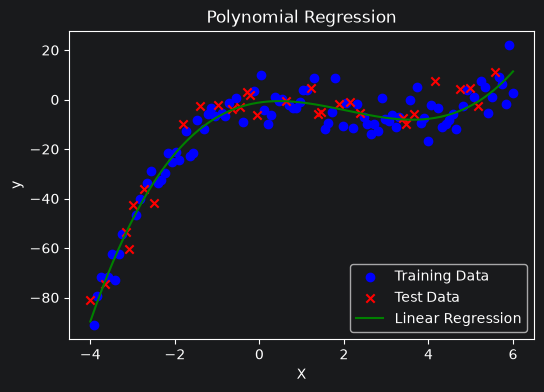

In [48]:
X_dense = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
y_dense_best = best_model.predict(X_grid)

plt.figure(figsize=(6, 4))
plt.scatter(X_train, y_train, color='blue', label='Training Data')
plt.scatter(X_test, y_test, color='red', label='Test Data', marker='x')
plt.plot(X_dense, y_dense_best, color='green', label='Linear Regression')
plt.title('Polynomial Regression')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.show()

In [70]:
def fit_metrics_for_degree(d):
    pipe = Pipeline([
    ("poly", PolynomialFeatures(degree=d,include_bias=False)),
    ("lin", LinearRegression())
])
    pipe.fit(X_train, y_train)
    ytr = pipe.predict(X_train)
    yte = pipe.predict(X_test)
    return  pipe, {
        "degree": d,
        "train_R2": r2_score(y_train, ytr),
        "test_R2": r2_score(y_test, yte),
        "train_rmse": root_mean_squared_error(y_train, ytr),
        "test_rmse": root_mean_squared_error(y_test, yte),
    }

model_low, m_low = fit_metrics_for_degree(1)
model_best, m_best = best_model, {
    "degree": best_degree,
    "train_R2": r2_score(y_train, best_model.predict(X_train)),
        "test_R2": r2_score(y_test, best_model.predict(X_test)),
        "train_rmse": root_mean_squared_error(y_train, best_model.predict(X_train)),
        "test_rmse": root_mean_squared_error(y_test, best_model.predict(X_test)),
}

model_high, m_high = fit_metrics_for_degree(10)
pd.DataFrame([m_low, m_best, m_high])

,degree,train_R2,test_R2,train_rmse,test_rmse
0,1,0.491911,0.532213,15.306701,16.844079
1,3,0.937389,0.943683,5.373235,5.844456
2,10,0.890489,0.921319,7.106260,6.908076


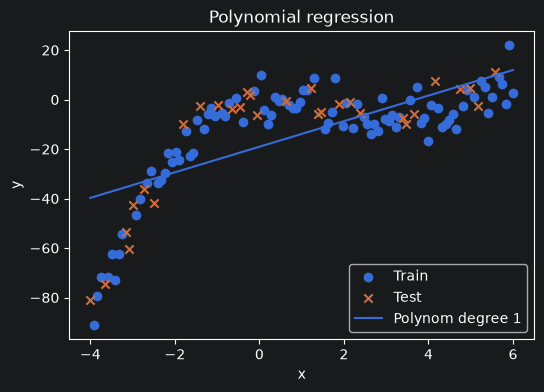

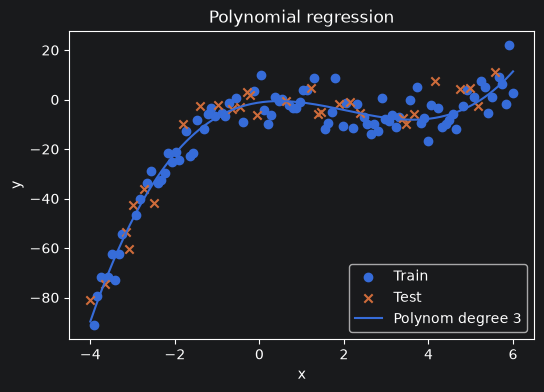

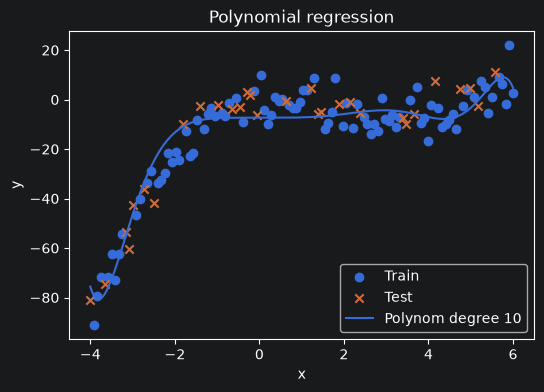

In [71]:
for d, model in [(1, model_low), (best_degree, model_best),(10, model_high)]:
    plt.figure(figsize=(6,4))
    y_curve = model.predict(X_dense)
    plt.scatter(X_train, y_train, label="Train")
    plt.scatter(X_test, y_test, label="Test", marker="x")
    plt.plot(X_dense, y_curve, label=f"Polynom degree {d}")
    plt.title("Polynomial regression")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()
    plt.show()